# Traffic Case Study Model: Rural Roads

Dataset: `traffic_case_study.xlsx`

### Note: Claude Opus 5.5 was used as an assistant

## Load the raw data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
case_study = pd.read_excel("traffic_case_study.xlsx")
case_study.shape

(600, 26)

In [3]:
case_study.head()

,AUTOMOBILE_COUNT,SPEED_LIMIT,URBAN_RURAL,URBAN,YOUNG_DRIVER,COLLISION_TYPE,LANE_COUNT,BICYCLE_COUNT,BUS_COUNT,ILLUMINATION,...,DRUGGED_DRIVER,FATAL_OR_SUSP_SERIOUS_INJ,FATIGUE_ASLEEP,HIT_FIXED_OBJECT,LANE_DEPARTURE,MATURE_DRIVER,OVERTURNED,SCHOOL_ZONE,SPEEDING_RELATED,WET_ROAD
0,1,25.0,4,1.0,0.0,2,2.0,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,35.0,4,1.0,0.0,2,4.0,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,25.0,1,0.0,1.0,7,2.0,0,0.0,1,...,0,0,0,1,1,0,0,0,0,0
3,0,35.0,4,1.0,0.0,7,2.0,0,0.0,1,...,1,0,0,1,1,0,0,0,1,0
4,3,35.0,4,1.0,0.0,2,2.0,0,0.0,1,...,0,0,0,0,1,1,0,0,0,0


## Missing values

In [4]:
nulls = case_study.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(len(nulls), "of", case_study.shape[1], "fields have null values\n")
print(nulls.to_string())

5 of 26 fields have null values

SPEED_LIMIT     60
URBAN           60
YOUNG_DRIVER    60
LANE_COUNT      60
BUS_COUNT       60


## Handling the missing values

The case-study rows are the first 600 rows of `features.xls` (every value they share matches), so the missing values are recovered from there.
Every fatal / serious crash is missing `SPEED_LIMIT`, so a mean or a "was missing" flag would give away the outcome. Recovering the real values avoids that.

| Field | Method |
|---|---|
| `SPEED_LIMIT` | Copied from `features.xls` |
| `LANE_COUNT` | Copied from `features.xls` |
| `BUS_COUNT` | Copied from `features.xls` |
| `YOUNG_DRIVER` | From the driver counts in `features.xls`: any driver aged 16–20 = 1 |
| `URBAN` | From `URBAN_RURAL`: 1 (rural) = 0, otherwise 1 |

In [5]:
source = pd.read_excel("features.xls").iloc[:600]

shared = [c for c in case_study.columns if c in source.columns]
both = case_study[shared].notna() & source[shared].notna()
print("Values that differ between the two files:", int(((case_study[shared] != source[shared]) & both).sum().sum()))

df = case_study.copy()
for col in ["SPEED_LIMIT", "LANE_COUNT", "BUS_COUNT"]:
    df[col] = df[col].fillna(source[col])
young_counts = ["DRIVER_COUNT_16YR", "DRIVER_COUNT_17YR", "DRIVER_COUNT_18YR", "DRIVER_COUNT_19YR", "DRIVER_COUNT_20YR"]
df["YOUNG_DRIVER"] = df["YOUNG_DRIVER"].fillna((source[young_counts].sum(axis=1) > 0).astype(float))
df["URBAN"] = df["URBAN"].fillna((df["URBAN_RURAL"] != 1).astype(float))

print("Missing values left:", df.isnull().sum().sum())

Values that differ between the two files: 0
Missing values left: 0


## Rural crashes only

The study focuses on rural roads, so only rural crashes (`URBAN_RURAL` = 1, i.e. `URBAN` = 0) are kept.

In [6]:
df = df[df["URBAN"] == 0].reset_index(drop=True)
print(f"{len(df)} rural crashes, {int(df['FATAL_OR_SUSP_SERIOUS_INJ'].sum())} fatal / serious")

125 rural crashes, 7 fatal / serious


## Data Cleaning

Drop complete duplicates: rows that are exact copies of another row.

In [7]:
n_before = len(df)
df = df[~df.duplicated()].reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate rows → {len(df)} rows, {int(df['FATAL_OR_SUSP_SERIOUS_INJ'].sum())} fatal / serious")

Dropped 11 duplicate rows → 114 rows, 6 fatal / serious


## Feature selection

### Step 1: Prepare the features

- Leave out the outcome `FATAL_OR_SUSP_SERIOUS_INJ`
- Drop `URBAN_RURAL` (same as `URBAN`)
- Split `COLLISION_TYPE` and `ILLUMINATION` into one yes/no column per code
- Drop columns that have the same value in every rural crash (e.g. `URBAN`)

In [8]:
TARGET = "FATAL_OR_SUSP_SERIOUS_INJ"
collision_names = {0: "NON_COLLISION", 1: "REAR_END", 2: "HEAD_ON", 3: "BACKING", 4: "ANGLE",
                   5: "SIDESWIPE_SAME_DIR", 6: "SIDESWIPE_OPP_DIR", 7: "HIT_FIXED_OBJECT",
                   8: "HIT_NON_MOTORIST", 98: "OTHER"}
light_names = {1: "DAYLIGHT", 2: "DARK_NO_LIGHTS", 3: "DARK_LIGHTS", 4: "DUSK", 5: "DAWN", 6: "DARK_UNKNOWN"}

y = df[TARGET]
X = df.drop(columns=[TARGET, "URBAN_RURAL", "COLLISION_TYPE", "ILLUMINATION"])
X = X.join(pd.get_dummies(df["COLLISION_TYPE"].map(collision_names), prefix="COLL").astype(int))
X = X.join(pd.get_dummies(df["ILLUMINATION"].map(light_names), prefix="LIGHT").astype(int))

constant = [c for c in X if X[c].nunique() == 1]          # same value in every rural crash
X = X.drop(columns=constant)
print("Dropped constant columns:", constant)
X.shape

Dropped constant columns: ['URBAN', 'BICYCLE_COUNT', 'PED_COUNT', 'SCHOOL_ZONE']


(114, 29)

### Step 2: Multicollinearity check

- Yes/no pair: chi-square test, strength = Cramér's V
- Pair with a count or number: Pearson's r
- Strength above 0.8: drop one of the pair · 0.7–0.8: marginal (keep both for now) · below 0.7: keep both

In [9]:
from itertools import combinations
import numpy as np
from scipy.stats import chi2_contingency, pearsonr

def association_pairs(X):
    yes_no = [c for c in X if X[c].between(0, 1).all()]
    rows = []
    for a, b in combinations(X.columns, 2):
        if a in yes_no and b in yes_no:
            both = X[a].isin([0, 1]) & X[b].isin([0, 1])          # skip mean-imputed values
            table = pd.crosstab(X.loc[both, a], X.loc[both, b])
            if min(table.shape) < 2:                               # one of them never varies in these rows
                strength, p, test = 0.0, 1.0, "Cramér's V"
            else:
                chi2, p, _, _ = chi2_contingency(table, correction=False)
                strength, test = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), "Cramér's V"
        else:
            r, p = pearsonr(X[a], X[b])
            strength, test = abs(r), "Pearson |r|"
        rows.append({"Feature A": a, "Feature B": b, "Test": test, "Strength": strength, "p-value": p})
    return pd.DataFrame(rows).sort_values("Strength", ascending=False).reset_index(drop=True)

pairs = association_pairs(X)
print(len(pairs), "pairs tested |", (pairs["Strength"] > 0.8).sum(), "above 0.8 |",
      pairs["Strength"].between(0.7, 0.8).sum(), "marginal (0.7–0.8)")

406 pairs tested | 3 above 0.8 | 0 marginal (0.7–0.8)


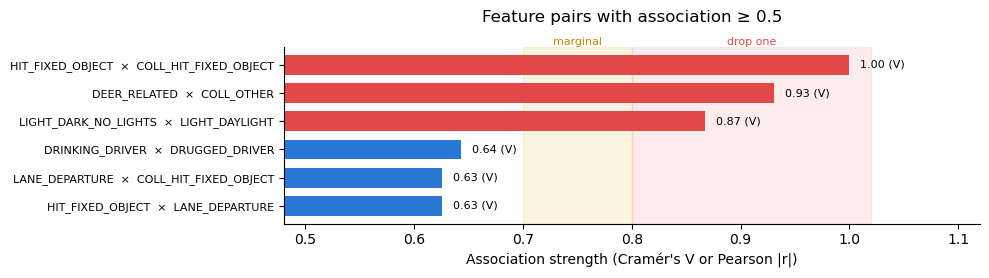

In [10]:
import matplotlib.pyplot as plt

def plot_pairs(pairs, title, min_strength=0.5):
    top = pairs[pairs["Strength"] >= min_strength].iloc[::-1]
    colors = ["#e34948" if s > 0.8 else "#eda100" if s >= 0.7 else "#2a78d6" for s in top["Strength"]]
    fig, ax = plt.subplots(figsize=(10, 0.28 * len(top) + 1.2))
    ax.axvspan(0.7, 0.8, color="#eda100", alpha=0.12)
    ax.axvspan(0.8, 1.02, color="#e34948", alpha=0.10)
    ax.barh(top["Feature A"] + "  ×  " + top["Feature B"], top["Strength"], color=colors, height=0.7)
    for i, (s, t) in enumerate(zip(top["Strength"], top["Test"])):
        ax.text(s + 0.01, i, f"{s:.2f} ({'V' if t.startswith('Cram') else 'r'})", va="center", fontsize=8)
    ax.set_xlim(min_strength - 0.02, 1.12)
    ax.set_xlabel("Association strength (Cramér's V or Pearson |r|)")
    ax.set_title(title, pad=18)
    ax.text(0.75, 1.0, "marginal", ha="center", va="bottom", fontsize=8, color="#c98500", transform=ax.get_xaxis_transform())
    ax.text(0.91, 1.0, "drop one", ha="center", va="bottom", fontsize=8, color="#e34948", transform=ax.get_xaxis_transform())
    ax.tick_params(axis="y", labelsize=8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.show()

plot_pairs(pairs, "Feature pairs with association ≥ 0.5")

**Pairs above 0.8: which one is dropped.** Rule: keep the original field, or the clearer column.

| Dropped | Kept | Reason |
|---|---|---|
| `COLL_HIT_FIXED_OBJECT` | `HIT_FIXED_OBJECT` | Identical |
| `COLL_OTHER` | `DEER_RELATED` | Deer crashes are coded "other"; "other" is not defined |
| `LIGHT_DAYLIGHT` | `LIGHT_DARK_NO_LIGHTS` | Rural crashes are almost all one or the other (near-opposites) |

In [11]:
X = X.drop(columns=["COLL_HIT_FIXED_OBJECT", "COLL_OTHER", "LIGHT_DAYLIGHT"])

pairs_after = association_pairs(X)
print(X.shape[1], "features left | strongest remaining pair:", round(pairs_after["Strength"].max(), 2))

26 features left | strongest remaining pair: 0.64


**Nested features.** Cramér's V misses a small flag that sits entirely inside a bigger one (e.g. every marijuana crash is also an impaired-driver crash). Rule: if 100% of feature A's crashes are also in feature B **and** they are the same concept by definition, keep only the broader B.

In [12]:
from itertools import permutations

# Same-concept groups (from the data dictionary)
families = {
    "Collision type": ["HIT_FIXED_OBJECT", "LANE_DEPARTURE", "OVERTURNED"] + [c for c in X if c.startswith("COLL_")],
    "Lighting": [c for c in X if c.startswith("LIGHT_")],
    "Speeding": ["SPEEDING_RELATED"],
    "Older driver": ["MATURE_DRIVER"],
}

rows = []
for concept, cols in families.items():
    cols = [c for c in cols if c in X]
    for a, b in permutations(cols, 2):
        ok = X[a].isin([0, 1]) & X[b].isin([0, 1])                       # skip mean-imputed values
        inside, outside = (X[a] == 1) & ok, (X[b] == 1) & ok
        if 0 < inside.sum() < outside.sum() and (inside & outside).sum() == inside.sum():
            rows.append({"Narrow feature": a, "Its crashes": int(inside.sum()), "Inside": b,
                         "Broad crashes": int(outside.sum()), "Concept": concept})
nested = pd.DataFrame(rows, columns=["Narrow feature", "Its crashes", "Inside", "Broad crashes", "Concept"])
narrow = sorted(set(nested["Narrow feature"]))
X = X.drop(columns=narrow)
print("Dropped nested features:", narrow if narrow else "none")
nested

Dropped nested features: none


,Narrow feature,Its crashes,Inside,Broad crashes,Concept


### Step 3: SelectKBest (chi-square)

- Score every feature by its chi-square association with `FATAL_OR_SUSP_SERIOUS_INJ` and keep the top 10
- Every column is first scaled to 0–1, so numbers like `SPEED_LIMIT` don't score higher just because of their units (yes/no columns are unchanged)
- Chi-square says how strongly a feature is linked to the outcome, not in which direction, so the severe rate when the feature = yes is shown next to it

In [13]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

print(f"Overall severe rate: {y.mean():.1%}")
X_scaled = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)
selector = SelectKBest(chi2, k=10).fit(X_scaled, y)

ranking = pd.DataFrame({
    "Chi-square": selector.scores_,
    "p-value": selector.pvalues_,
    "Severe rate when yes": [y[X[c] == 1].mean() if X[c].isin([0, 1]).all() else np.nan for c in X],   # yes/no features only
}, index=X.columns).sort_values("Chi-square", ascending=False)
ranking["Selected"] = ranking.index.isin(X.columns[selector.get_support()])

top10 = ranking.index[ranking["Selected"]].tolist()
ranking.head(10).style.format({"Chi-square": "{:.2f}", "p-value": "{:.4f}", "Severe rate when yes": "{:.1%}"}, na_rep="–")

Overall severe rate: 5.3%


,Chi-square,p-value,Severe rate when yes,Selected
UNBELTED_OCC_COUNT,28.74,0.0000,38.5%,True
WET_ROAD,9.50,0.0021,21.1%,True
SPEEDING_RELATED,2.88,0.0896,11.8%,True
CURVED_ROAD,1.72,0.1894,0.0%,True
LANE_DEPARTURE,1.41,0.2356,9.3%,True
LIGHT_DARK_NO_LIGHTS,1.39,0.2386,0.0%,True
DEER_RELATED,0.94,0.3311,0.0%,True
YOUNG_DRIVER,0.89,0.3458,0.0%,True
HIT_FIXED_OBJECT,0.75,0.3861,8.0%,True
OVERTURNED,0.62,0.4321,11.1%,True


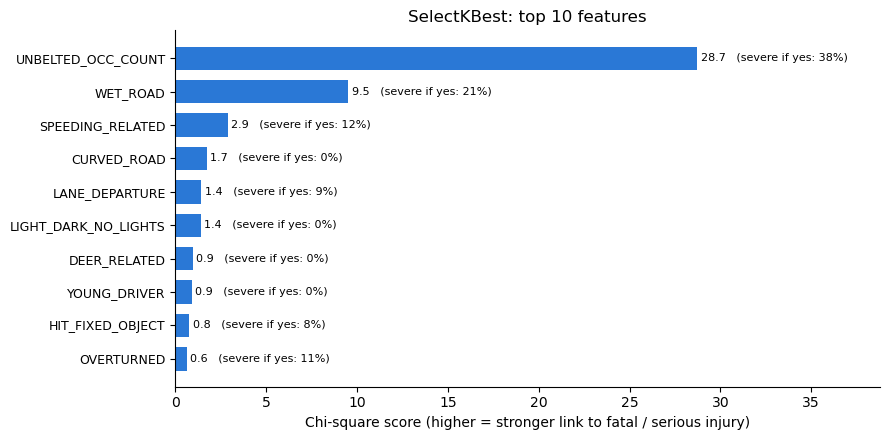

In [14]:
top = ranking.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top["Chi-square"], color="#2a78d6", height=0.7)
for i, (score, rate) in enumerate(zip(top["Chi-square"], top["Severe rate when yes"])):
    ax.text(score + 0.2, i, f"{score:.1f}   (severe if yes: {rate:.0%})" if pd.notna(rate) else f"{score:.1f}", va="center", fontsize=8)
ax.set_xlabel("Chi-square score (higher = stronger link to fatal / serious injury)")
ax.set_title("SelectKBest: top 10 features")
ax.set_xlim(0, top["Chi-square"].max() * 1.35)
ax.tick_params(axis="y", labelsize=9)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## Model

- Features: the top 10 from SelectKBest
- Logistic regression with an L2 penalty (`C = 1.0`); features are standardized first
- Class imbalance handled with `class_weight="balanced"`
- 5-fold stratified cross-validation, repeated 10 times (50 test folds)

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, make_scorer, precision_score, f1_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
CLASS_LABELS = ["Not severe", "Fatal / serious injury"]
CLASS_COLORS = ["#a9a8a2", "#e34948"]

In [16]:
X_model = X[top10]
y_model = y

### Class imbalance

Few crashes are severe, so an unweighted model would predict "not severe" for everyone. Balanced class weights give each severe crash more weight, so both classes count equally in training.

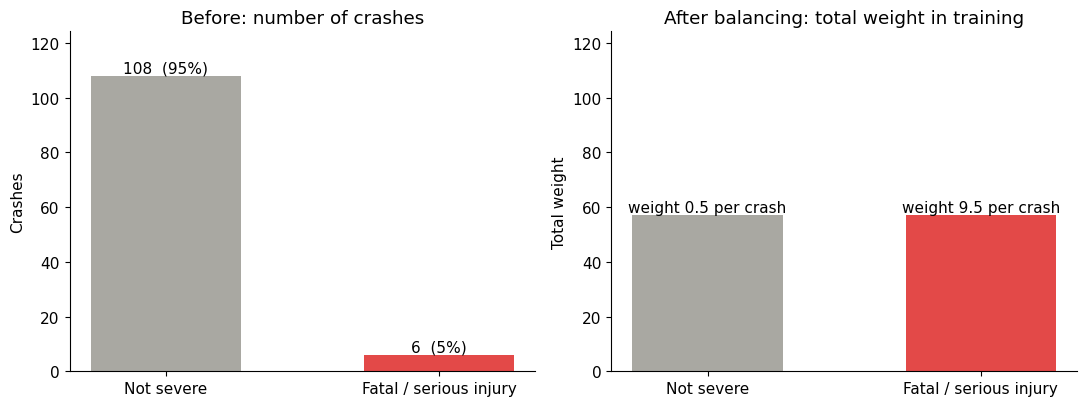

In [17]:
counts = y_model.value_counts().sort_index()
weight_per_crash = len(y_model) / (2 * counts)          # what class_weight="balanced" uses

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axes[0].bar(CLASS_LABELS, counts, color=CLASS_COLORS, width=0.55)
for bar, n in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, n, f"{n}  ({n / len(y_model):.0%})", ha="center", va="bottom")
axes[0].set_title("Before: number of crashes")
axes[0].set_ylabel("Crashes")

bars = axes[1].bar(CLASS_LABELS, counts * weight_per_crash, color=CLASS_COLORS, width=0.55)
for bar, w in zip(bars, weight_per_crash):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"weight {w:.1f} per crash", ha="center", va="bottom")
axes[1].set_title("After balancing: total weight in training")
axes[1].set_ylabel("Total weight")
for ax in axes:
    ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()

### Cross-validated results

In [18]:
model = make_pipeline(StandardScaler(),
                      LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000))   # L2 penalty is the default
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": make_scorer(f1_score, zero_division=0), "roc_auc": "roc_auc"}
scores = cross_validate(model, X_model, y_model, cv=cv, scoring=scoring)

metric_names = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "roc_auc": "ROC AUC"}
results = pd.DataFrame({"Mean": [scores[f"test_{m}"].mean() for m in metric_names],
                        "Std": [scores[f"test_{m}"].std() for m in metric_names]},
                       index=metric_names.values()).round(3)
results

,Mean,Std
Accuracy,0.916,0.050
Precision,0.311,0.278
Recall,0.640,0.459
F1,0.394,0.305
ROC AUC,0.909,0.149


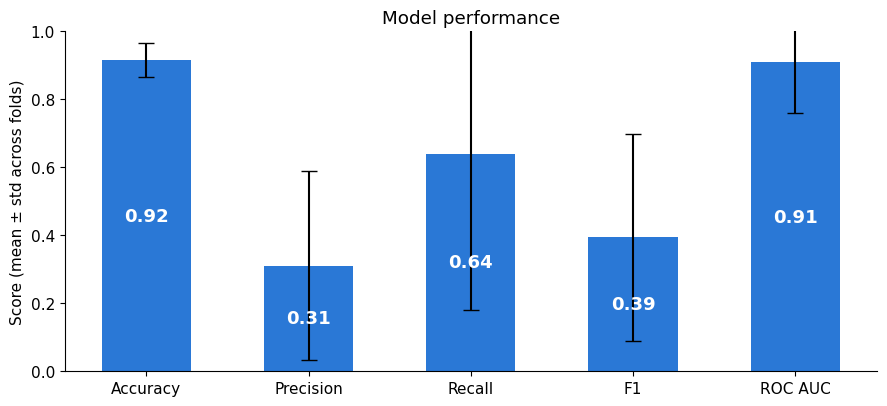

In [19]:
main = results.loc[["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]]
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(main.index, main["Mean"], yerr=main["Std"], capsize=6, color="#2a78d6", width=0.55)
for bar, v in zip(bars, main["Mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v / 2, f"{v:.2f}", ha="center", va="center",
            color="white", fontsize=13, fontweight="bold")
ax.set_ylim(0, 1)
ax.set_ylabel("Score (mean ± std across folds)")
ax.set_title("Model performance")
plt.tight_layout()
plt.show()

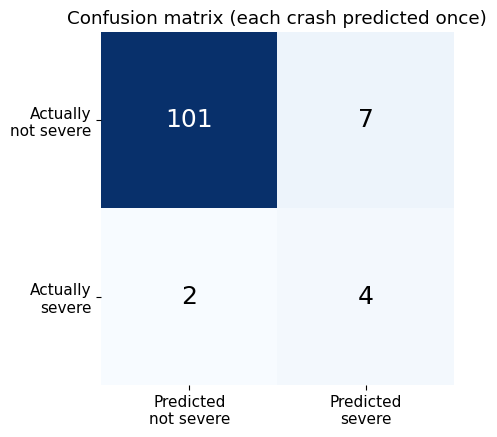

In [20]:
pred = cross_val_predict(model, X_model, y_model, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
cm = confusion_matrix(y_model, pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", fontsize=18, color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted\nnot severe", "Predicted\nsevere"])
ax.set_yticks([0, 1], ["Actually\nnot severe", "Actually\nsevere"])
ax.set_title("Confusion matrix (each crash predicted once)")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

### ROC curve and AUC

How well the model ranks severe crashes above non-severe ones. 0.5 = random guessing, 1.0 = perfect.

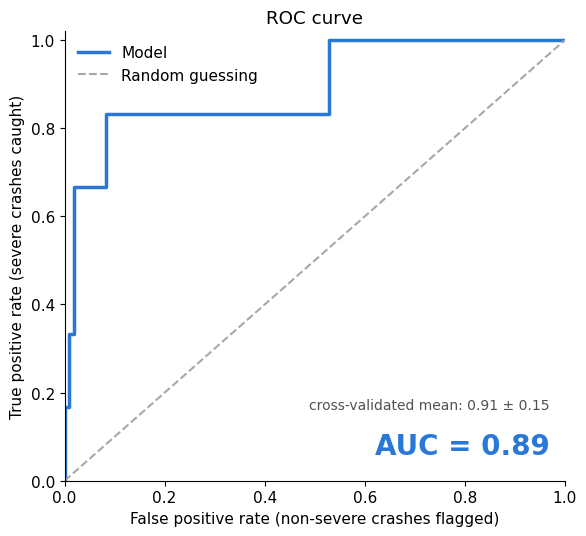

In [21]:
from sklearn.metrics import roc_curve, roc_auc_score

prob = cross_val_predict(model, X_model, y_model, method="predict_proba",
                         cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))[:, 1]
fpr, tpr, _ = roc_curve(y_model, prob)
auc = roc_auc_score(y_model, prob)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot(fpr, tpr, color="#2a78d6", linewidth=2.5, label="Model")
ax.plot([0, 1], [0, 1], color="#a9a8a2", linestyle="--", linewidth=1.5, label="Random guessing")
ax.text(0.97, 0.06, f"AUC = {auc:.2f}", transform=ax.transAxes, ha="right", fontsize=20, fontweight="bold", color="#2a78d6")
ax.text(0.97, 0.16, f"cross-validated mean: {results.loc['ROC AUC', 'Mean']:.2f} ± {results.loc['ROC AUC', 'Std']:.2f}",
        transform=ax.transAxes, ha="right", fontsize=10, color="#52514e")
ax.set_xlabel("False positive rate (non-severe crashes flagged)")
ax.set_ylabel("True positive rate (severe crashes caught)")
ax.set_title("ROC curve")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

### Feature importance

Coefficients of the model fitted on all rows. Features are standardized, so the bar lengths are comparable: red raises the risk of a fatal / serious injury, blue lowers it.

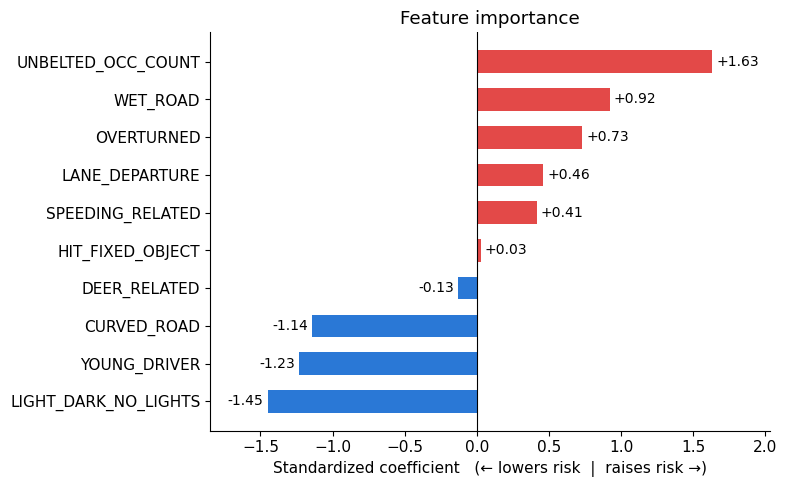

In [22]:
model.fit(X_model, y_model)
coef = pd.Series(model[-1].coef_[0], index=X_model.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coef.index, coef, color=["#e34948" if c > 0 else "#2a78d6" for c in coef], height=0.6)
for i, c in enumerate(coef):
    ax.text(c + (0.03 if c > 0 else -0.03), i, f"{c:+.2f}", va="center", ha="left" if c > 0 else "right", fontsize=10)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(coef.min() - 0.4, coef.max() + 0.4)
ax.set_xlabel("Standardized coefficient   (← lowers risk  |  raises risk →)")
ax.set_title("Feature importance")
plt.tight_layout()
plt.show()

### VIF check

VIF above 5 would signal multicollinearity.

In [23]:
X_const = sm.add_constant(X_model.astype(float))
vif = pd.DataFrame({"VIF": [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])]},
                   index=X_model.columns).round(2).sort_values("VIF", ascending=False)
vif

,VIF
HIT_FIXED_OBJECT,2.44
LANE_DEPARTURE,1.75
CURVED_ROAD,1.50
SPEEDING_RELATED,1.41
WET_ROAD,1.35
DEER_RELATED,1.27
OVERTURNED,1.24
LIGHT_DARK_NO_LIGHTS,1.21
UNBELTED_OCC_COUNT,1.13
YOUNG_DRIVER,1.08


## Results (rural roads)

114 rural crashes, 6 fatal / serious.

**Features (10):** UNBELTED_OCC_COUNT, WET_ROAD, SPEEDING_RELATED, CURVED_ROAD, LANE_DEPARTURE, LIGHT_DARK_NO_LIGHTS, DEER_RELATED, YOUNG_DRIVER, HIT_FIXED_OBJECT, OVERTURNED

| Accuracy | Precision | Recall | F1 |
|---|---|---|---|
| 0.92 | 0.31 | 0.64 | 0.39 |

- Strongest risk factors: unbelted occupants, wet road, overturned vehicle
- No nested features of the same concept were found
- Only 6 severe crashes: just the first 2 features are clearly linked to the outcome (p < 0.05), and the scores swing widely between folds (recall ± 0.46). Treat these results as very rough
- All VIFs < 2.5: no multicollinearity